# 02 · Evaluate two transparent baselines

**Question:** How often does the largest standardized mean shift identify
the service where a fault was injected?

Both baselines are heuristics, not trained ML models. Their measured
failures motivate the later learning problem. All tables are computed below.

In [1]:
from pathlib import Path
import os
import sys
ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'src/rca').is_dir(), 'Open this notebook from the project folder.'
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from rca.data import list_cases, load_case, service_names
from rca.analysis import configure_plots
np.random.seed(42)
configure_plots()
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)

## 1. The rule and evaluation setting

For metric $m$, $z_m = |\mu_{post,m}-\mu_{pre,m}|/(s_{pre,m}+10^{-8})$.
A service's score is the **maximum** of its metric scores. We use sample
standard deviation ($ddof=1$), all available `time < inject_time` rows,
and all available `time >= inject_time` rows. Ties use alphabetical order.

- `zscore` keeps every metric.
- `zscore_nonconst` ignores metrics whose normal-window standard deviation
  is exactly zero. For those, the denominator is just $10^{-8}$, so any
  blip after injection gets an enormous score (see notebook 01, section 6).

Injection time is supplied. No root labels, fault labels, case names,
or future cases are input features. Full post-injection recordings are
available, so this experiment is **offline localization**, not online
incident detection or a held-out learned-model test.

In [2]:
from rca.evaluate import run_evaluation
runs = {method: run_evaluation(method=method) for method in ['zscore', 'zscore_nonconst']}
per_case, summary = runs['zscore_nonconst']
comparison = pd.concat({method: result[1] for method, result in runs.items()}, names=['method']).reset_index(level=0)
display(comparison.loc[comparison['scope'].eq('overall'),
                       ['method', 'evaluation_set', 'n_cases', 'AC@1', 'AC@3', 'AC@5', 'Avg@5']]
        .style.format({name: '{:.2%}' for name in ['AC@1', 'AC@3', 'AC@5', 'Avg@5']}).hide(axis='index'))

evaluation_set      scope fault_type  n_cases  n_evaluable   AC@1   AC@2   AC@3   AC@4   AC@5  Avg@5
     all_cases    overall        all      125          123 0.4960 0.8080 0.8800 0.9200 0.9360 0.8080
     all_cases fault_type        cpu       25           24 0.4800 0.9200 0.9200 0.9600 0.9600 0.8480
     all_cases fault_type      delay       25           25 0.4800 0.8000 0.9600 1.0000 1.0000 0.8480
     all_cases fault_type       disk       25           25 0.8400 0.9600 1.0000 1.0000 1.0000 0.9600
     all_cases fault_type       loss       25           24 0.2000 0.4400 0.5200 0.6400 0.7200 0.5040
     all_cases fault_type        mem       25           25 0.4800 0.9200 1.0000 1.0000 1.0000 0.8800
evaluable_only    overall        all      123          123 0.5041 0.8211 0.8943 0.9350 0.9512 0.8211
evaluable_only fault_type        cpu       24           24 0.5000 0.9583 0.9583 1.0000 1.0000 0.8833
evaluable_only fault_type      delay       25           25 0.4800 0.8000 0.9600 1.0000 1.00

evaluation_set      scope fault_type  n_cases  n_evaluable   AC@1   AC@2   AC@3   AC@4   AC@5  Avg@5
     all_cases    overall        all      125          123 0.7600 0.8800 0.9040 0.9360 0.9840 0.8928
     all_cases fault_type        cpu       25           24 0.7600 0.9200 0.9600 0.9600 0.9600 0.9120
     all_cases fault_type      delay       25           25 0.9200 1.0000 1.0000 1.0000 1.0000 0.9840
     all_cases fault_type       disk       25           25 0.9200 0.9600 1.0000 1.0000 1.0000 0.9760
     all_cases fault_type       loss       25           24 0.3200 0.5200 0.5600 0.7200 0.9600 0.6160
     all_cases fault_type        mem       25           25 0.8800 1.0000 1.0000 1.0000 1.0000 0.9760
evaluable_only    overall        all      123          123 0.7724 0.8943 0.9187 0.9512 1.0000 0.9073
evaluable_only fault_type        cpu       24           24 0.7917 0.9583 1.0000 1.0000 1.0000 0.9500
evaluable_only fault_type      delay       25           25 0.9200 1.0000 1.0000 1.0000 1.00

method,evaluation_set,n_cases,AC@1,AC@3,AC@5,Avg@5
zscore,all_cases,125,49.60%,88.00%,93.60%,80.80%
zscore,evaluable_only,123,50.41%,89.43%,95.12%,82.11%
zscore_nonconst,all_cases,125,76.00%,90.40%,98.40%,89.28%
zscore_nonconst,evaluable_only,123,77.24%,91.87%,100.00%,90.73%


## 2. Read the metrics correctly

**AC@k** is the fraction of cases with the annotated root in the first k
positions. **Avg@5** is the mean of AC@1, AC@2, AC@3, AC@4, and AC@5;
it is not average precision or mean reciprocal rank.

`all_cases` includes all 125 supplied cases, counting invalid-window cases
as misses. `evaluable_only` reports the 123 cases with valid windows.
Both denominators are shown to prevent silent dataset exclusions.
The chart compares both baselines per fault type on all 125 cases.

,case_id,fault_type,status,error
90,re1ob_currencyservice_loss_1,loss,invalid_window,Need >=2 pre and >=1 post rows; observed pre=0...
102,re1ob_productcatalogservice_cpu_3,cpu,invalid_window,Need >=2 pre and >=1 post rows; observed pre=6...


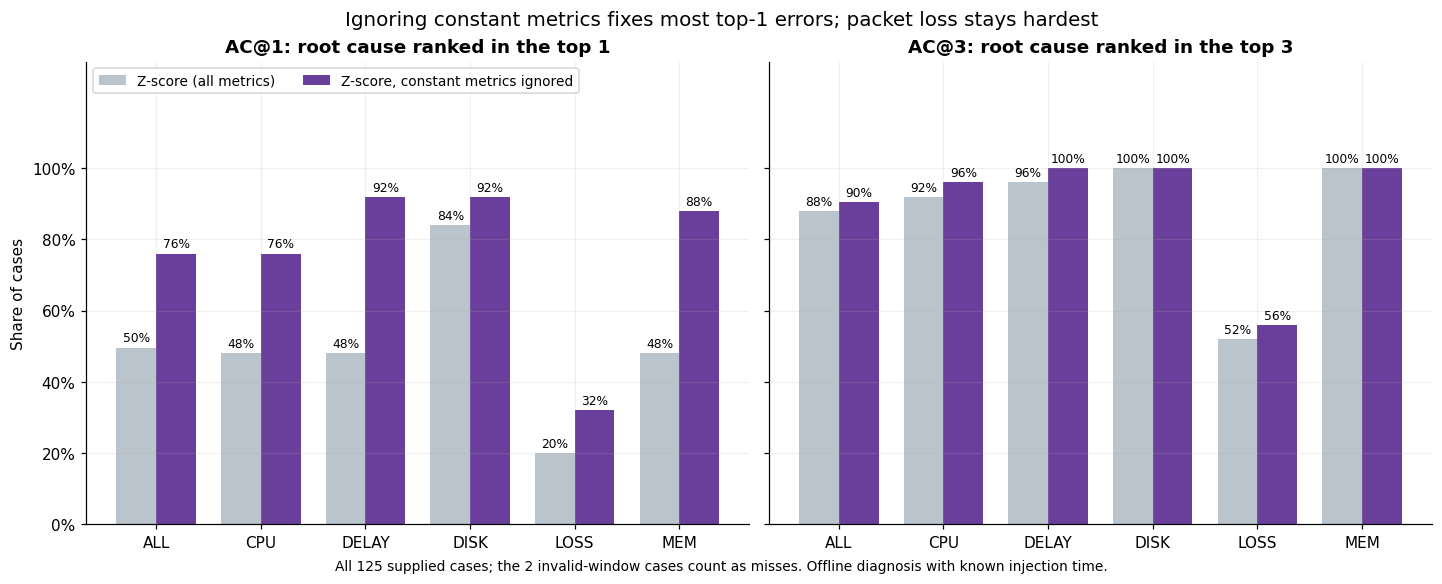

In [3]:
invalid = per_case.loc[per_case['status'].ne('ok'), ['case_id', 'fault_type', 'status', 'error']]
display(invalid)
from rca.analysis import plot_baseline_comparison
fig = plot_baseline_comparison({method: result[1] for method, result in runs.items()})
plt.show()

## 3. The five worst ranked, evaluable incidents (stronger baseline)

Sort by the annotated root's rank under `zscore_nonconst`, descending,
then case ID. These are the failures that remain after the scaling fix.
The two unscorable recordings are listed above rather than being
described as model-generated rankings.

In [4]:
def worst_cases(frame):
    return frame.loc[frame['status'].eq('ok')].sort_values(
        ['rank_of_true_root', 'case_id'], ascending=[False, True]).head(5)
for method, (frame, _) in runs.items():
    worst_cases(frame).to_csv(RESULTS / f'{method}_worst_cases.csv', index=False)
worst = worst_cases(per_case)
display(worst[['case_id', 'fault_type', 'true_root', 'rank_of_true_root', 'predicted_ranking']])

,case_id,fault_type,true_root,rank_of_true_root,predicted_ranking
65,re1ob_checkoutservice_loss_1,loss,checkoutservice,5.0,"[""paymentservice"", ""recommendationservice"", ""c..."
69,re1ob_checkoutservice_loss_5,loss,checkoutservice,5.0,"[""productcatalogservice"", ""paymentservice"", ""e..."
116,re1ob_productcatalogservice_loss_2,loss,productcatalogservice,5.0,"[""checkoutservice"", ""recommendationservice"", ""..."
117,re1ob_productcatalogservice_loss_3,loss,productcatalogservice,5.0,"[""checkoutservice"", ""recommendationservice"", ""..."
118,re1ob_productcatalogservice_loss_4,loss,productcatalogservice,5.0,"[""checkoutservice"", ""adservice"", ""recommendati..."


## 4. Explain two failures using actual measurements

The following Markdown notes were generated from this pinned dataset's
measured `zscore_nonconst` scores. The verification cell below checks that they still
agree with the recomputed worst cases. Interpretations are hypotheses.

# Two measured baseline failure cases

### re1ob_checkoutservice_loss_1

The annotated root `checkoutservice` ranks **5**. The services/candidates above it are `paymentservice`, `recommendationservice`, `cartservice`, `productcatalogservice`.

| service               | winning_metric   |   score |   pre_std_of_winner |
|:----------------------|:-----------------|--------:|--------------------:|
| paymentservice        | latency-90       | 377.07  |          2.8107e-05 |
| recommendationservice | mem              | 191.56  |       1183.6        |
| cartservice           | latency-90       | 144.7   |          9.34e-05   |
| productcatalogservice | latency-90       |  59.02  |          6.0153e-06 |
| checkoutservice       | mem              |  20.336 |          1.4034e+05 |

**Observed:** the maximum standardized mean shift is larger for these candidates. **Possible explanation:** packet loss can affect callers and request/error metrics, while unrelated resource drift can also score highly. The heuristic does not model dependencies or temporal propagation. These measurements alone do not establish which non-root changes were caused by the injected fault.


### re1ob_checkoutservice_loss_5

The annotated root `checkoutservice` ranks **5**. The services/candidates above it are `productcatalogservice`, `paymentservice`, `emailservice`, `recommendationservice`.

| service               | winning_metric   |   score |   pre_std_of_winner |
|:----------------------|:-----------------|--------:|--------------------:|
| productcatalogservice | latency-90       | 20.499  |          1.8333e-05 |
| paymentservice        | latency-90       | 10.623  |          2.9521e-05 |
| emailservice          | latency-90       |  7.7992 |          2.7547e-05 |
| recommendationservice | mem              |  7.5588 |      17362          |
| checkoutservice       | latency-50       |  4.1954 |          0.078675   |

**Observed:** the maximum standardized mean shift is larger for these candidates. **Possible explanation:** packet loss can affect callers and request/error metrics, while unrelated resource drift can also score highly. The heuristic does not model dependencies or temporal propagation. These measurements alone do not establish which non-root changes were caused by the injected fault.

In [5]:
from rca.analysis import worst_case_explanation
case_by_id = {case.case_id: case for case in list_cases()}
regenerated = '# Two measured baseline failure cases\n\n' + '\n\n'.join(
    worst_case_explanation(case_by_id[row.case_id], skip_constant=True) for row in worst.head(2).itertuples())
saved_explanation = (ROOT / 'docs/failure_analysis.md').read_text(encoding='utf-8')
assert regenerated == saved_explanation, 'Failure notes changed; regenerate the notebooks.'
print('Both Markdown explanations agree with the recomputed evidence.')

Both Markdown explanations agree with the recomputed evidence.


## 5. What comes next

Ignoring constant metrics was the first scaling fix; next try robust
scaling (median/MAD) and other aggregations as stronger statistical
comparisons. Then learn an anomaly representation and compare
a service-independent ranker with a graph model using a verified dependency
graph. Divide training and testing by whole incidents; later reserve an
entire application for cross-system testing. Do not randomly split rows
from one recording across training and testing.

A learned GNN, cross-system test, Docker, Kubernetes, and new fault-injection
runs are **not implemented this week**. BARO is optional and not reproduced
in this environment; see the README for the package-compatibility reason.

Outputs in `results/`, for each method `zscore` and `zscore_nonconst`:
`<method>_per_case.csv`, `<method>_summary.csv`, `<method>_protocol.json`,
`<method>_worst_cases.csv`; plus `fig_baseline_comparison.png`.